# 03 - Modelling and Evaluation

## Objectives

* Answer **business requirement 2**: predict whether a cherry leaf is healthy or has powdery mildew.
* Train and compare two model versions, evaluate the chosen one on unseen test images and check it against the business target of **97% accuracy**.

## Inputs

* `inputs/cherry_leaves_dataset/cherry-leaves/train`, `validation` and `test`
* `outputs/v1/image_shape.pkl`

## Outputs

* Augmented image examples
* Class indices (`class_names.pkl`)
* Trained model (`mildew_detector_model.keras`)
* Learning curves, model comparison, test evaluation and confusion matrix

## Additional comments

* Training on a laptop CPU can take 10-30 minutes. You can work on the dashboard while it runs.

---

# Change working directory

The notebooks live in `jupyter_notebooks/`, but all paths in this project are relative to the repository root, so we move one folder up.

In [1]:
import os

current_dir = os.getcwd()
if os.path.basename(current_dir) == 'jupyter_notebooks':
    os.chdir(os.path.dirname(current_dir))
print('Working directory:', os.getcwd())

Working directory: /Users/mlamleli/Documents/Mlamleli Projects/mildew-detector


---

# Imports, paths and settings

In [2]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import confusion_matrix, classification_report

my_data_dir = os.path.join('inputs', 'cherry_leaves_dataset', 'cherry-leaves')
train_path = os.path.join(my_data_dir, 'train')
val_path = os.path.join(my_data_dir, 'validation')
test_path = os.path.join(my_data_dir, 'test')

version = 'v1'
file_path = os.path.join('outputs', version)

image_shape = joblib.load(os.path.join(file_path, 'image_shape.pkl'))
BATCH_SIZE = 20
EPOCHS = 25          # early stopping usually ends training sooner
TARGET_ACCURACY = 0.97
SEED = 42
tf.random.set_seed(SEED)
print('Image shape:', image_shape)

Image shape: (128, 128, 3)


---

# Load images from folders into memory

Keras reads the images straight from the folders. The folder names become the labels (sorted alphabetically: `healthy` = 0, `powdery_mildew` = 1).

In [3]:
def load_set(path, shuffle):
    return tf.keras.utils.image_dataset_from_directory(
        path, image_size=image_shape[:2], batch_size=BATCH_SIZE,
        label_mode='binary', shuffle=shuffle, seed=SEED)


train_set = load_set(train_path, shuffle=True)
validation_set = load_set(val_path, shuffle=False)
test_set = load_set(test_path, shuffle=False)

class_names = train_set.class_names
joblib.dump(value=class_names, filename=os.path.join(file_path, 'class_names.pkl'))
print('Classes:', class_names)

Found 2944 files belonging to 2 classes.
Found 420 files belonging to 2 classes.
Found 844 files belonging to 2 classes.
Classes: ['healthy', 'powdery_mildew']


---

# Image augmentation

Augmentation creates slightly changed copies of the training images on the fly (flipped, rotated, zoomed). The model sees more variety, which helps it **generalise** to new photos and reduces **overfitting**. Augmentation is only active during training.

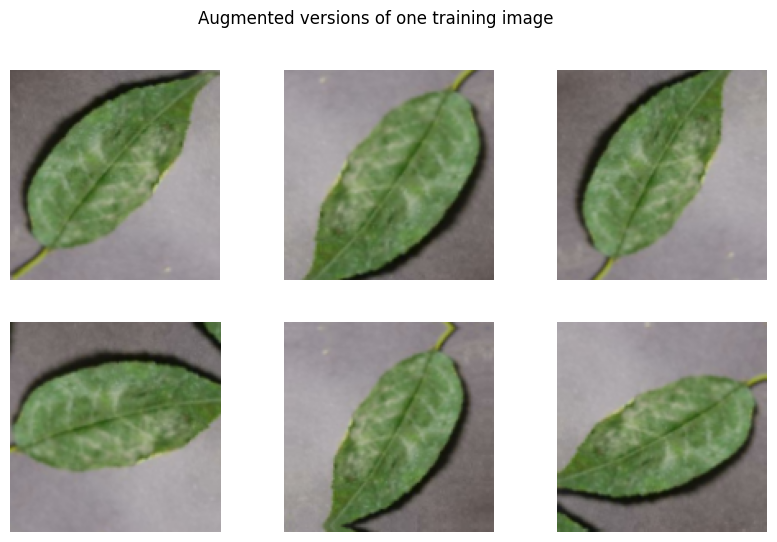

In [4]:
data_augmentation = models.Sequential([
    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name='augmentation')

# Show the same training image augmented 6 times
images, _ = next(iter(train_set))
plt.figure(figsize=(10, 6))
for i in range(6):
    augmented = data_augmentation(images[:1], training=True)
    ax = plt.subplot(2, 3, i + 1)
    plt.imshow(augmented[0].numpy().astype('uint8'))
    plt.axis('off')
plt.suptitle('Augmented versions of one training image')
plt.savefig(os.path.join(file_path, 'augmented_images.png'), bbox_inches='tight', dpi=100)
plt.show()

---

# Model architecture

A **Convolutional Neural Network (CNN)** learns visual patterns (edges, textures, white patches).

* `Rescaling(1/255)` - scales pixels to 0-1 inside the model, so the dashboard can pass raw images.
* 3 x `Conv2D` + `MaxPooling2D` blocks - detect increasingly complex patterns while shrinking the image.
* `Flatten` + `Dense(128, relu)` - combine the patterns into a decision.
* `Dropout` - randomly switches off neurons during training to **prevent overfitting**.
* `Dense(1, sigmoid)` - outputs the probability that the leaf has powdery mildew.

Compiled with the **Adam** optimiser and **binary cross-entropy** loss, the standard choice for a two-class problem.

In [5]:
def create_model(use_augmentation=True, dropout_rate=0.5):
    """Build and compile the CNN. Options let us compare versions."""
    model = models.Sequential(name='mildew_detector')
    model.add(layers.Input(shape=image_shape))
    if use_augmentation:
        model.add(data_augmentation)
    model.add(layers.Rescaling(1.0 / 255))

    model.add(layers.Conv2D(32, (3, 3), activation='relu'))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Conv2D(64, (3, 3), activation='relu'))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Conv2D(64, (3, 3), activation='relu'))
    model.add(layers.MaxPooling2D((2, 2)))

    model.add(layers.Flatten())
    model.add(layers.Dense(128, activation='relu'))
    model.add(layers.Dropout(dropout_rate))
    model.add(layers.Dense(1, activation='sigmoid'))

    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model


create_model().summary()

Model: "mildew_detector"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,605,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,662,209 (6.34 MB)

 Trainable params: 1,662,209 (6.34 MB)

 Non-trainable params: 0 (0.00 B)

---

# Train and compare two model versions

We train two versions to document how we reached the final model:

| Version | Augmentation | Dropout |
|---|---|---|
| A - baseline | No | 0.2 |
| B - regularised | Yes | 0.5 |

**Early stopping** watches the validation loss and stops training when it no longer improves for 3 epochs, then restores the best weights. This also prevents overfitting.

In [6]:
experiments = {
    'A_baseline': dict(use_augmentation=False, dropout_rate=0.2),
    'B_regularised': dict(use_augmentation=True, dropout_rate=0.5),
}

trained_models, histories = {}, {}
for name, params in experiments.items():
    print(f'\n===== Training model {name} =====')
    model = create_model(**params)
    early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
    history = model.fit(train_set, validation_data=validation_set,
                        epochs=EPOCHS, callbacks=[early_stop], verbose=1)
    trained_models[name] = model
    histories[name] = pd.DataFrame(history.history)


===== Training model A_baseline =====
Epoch 1/25


/Users/mlamleli/Documents/Mlamleli Projects/mildew-detector/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


148/148 ━━━━━━━━━━━━━━━━━━━━ 14s 93ms/step - accuracy: 0.9164 - loss: 0.1819 - val_accuracy: 0.9976 - val_loss: 0.0407
Epoch 2/25
148/148 ━━━━━━━━━━━━━━━━━━━━ 13s 84ms/step - accuracy: 0.9847 - loss: 0.0422 - val_accuracy: 0.9976 - val_loss: 0.0481
Epoch 3/25
148/148 ━━━━━━━━━━━━━━━━━━━━ 13s 85ms/step - accuracy: 0.9980 - loss: 0.0072 - val_accuracy: 0.9714 - val_loss: 0.1429
Epoch 4/25
148/148 ━━━━━━━━━━━━━━━━━━━━ 13s 85ms/step - accuracy: 0.9898 - loss: 0.0341 - val_accuracy: 0.9857 - val_loss: 0.1203

===== Training model B_regularised =====
Epoch 1/25
148/148 ━━━━━━━━━━━━━━━━━━━━ 16s 102ms/step - accuracy: 0.8145 - loss: 0.3835 - val_accuracy: 0.9643 - val_loss: 0.1264
Epoch 2/25
148/148 ━━━━━━━━━━━━━━━━━━━━ 15s 102ms/step - accuracy: 0.9477 - loss: 0.1436 - val_accuracy: 0.9976 - val_loss: 0.0454
Epoch 3/25
148/148 ━━━━━━━━━━━━━━━━━━━━ 16s 111ms/step - accuracy: 0.9779 - loss: 0.0672 - val_accuracy: 0.9524 - val_loss: 0.2033
Epoch 4/25
148/148 ━━━━━━━━━━━━━━━━━━━━ 18s 120ms/step -

In [7]:
# Compare the versions on the validation set (the test set stays untouched)
comparison = []
for name, model in trained_models.items():
    val_loss, val_acc = model.evaluate(validation_set, verbose=0)
    comparison.append({'Model': name, 'Epochs trained': len(histories[name]),
                       'Validation loss': round(val_loss, 4),
                       'Validation accuracy': round(val_acc, 4)})
df_comparison = pd.DataFrame(comparison)
df_comparison.to_csv(os.path.join(file_path, 'model_comparison.csv'), index=False)
df_comparison

,Model,Epochs trained,Validation loss,Validation accuracy
0,A_baseline,4,0.0407,0.9976
1,B_regularised,5,0.0454,0.9976


In [8]:
# Pick the version with the lowest validation loss
best_name = df_comparison.sort_values('Validation loss').iloc[0]['Model']
model = trained_models[best_name]
history_df = histories[best_name]
history_df.to_csv(os.path.join(file_path, 'training_history.csv'), index=False)
print('Chosen model:', best_name)

Chosen model: A_baseline


**Model choice:** both versions reached the same validation accuracy of 99.76% (1 wrong out of 420 images). Version A (no augmentation, dropout 0.2) had a slightly lower validation loss (0.0407 vs 0.0454 for version B), so it was selected as the final model.

The difference between the two is very small. Version B, with augmentation and stronger dropout, may cope better with photos taken in different lighting or angles, so it would be worth retesting both on real field photos from the client.

---

# Learning curves

If the training and validation lines stay close together, the model is learning patterns that generalise rather than memorising the training images.

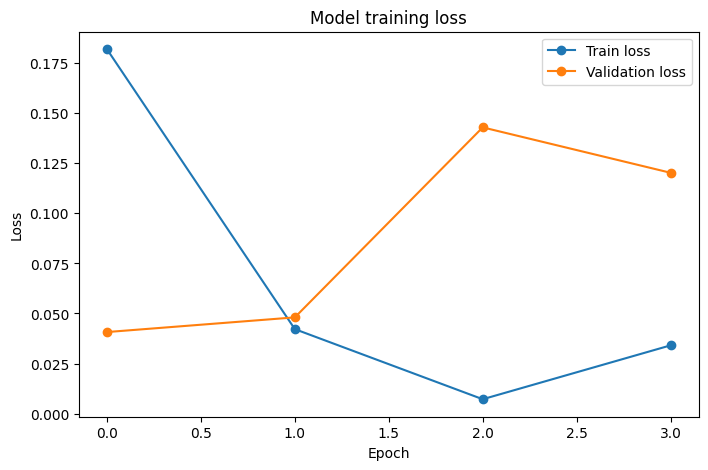

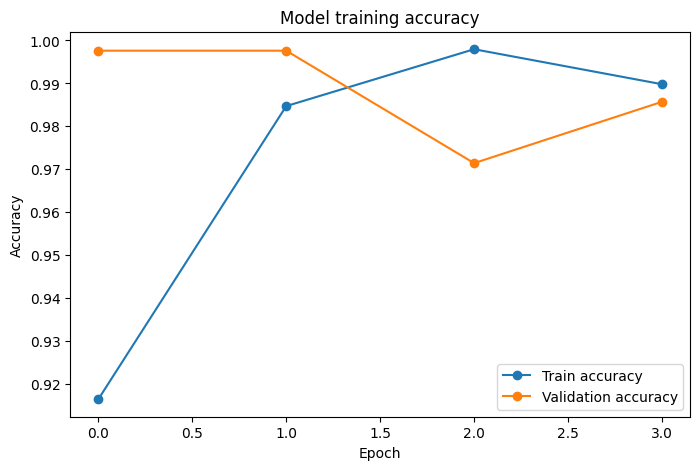

In [9]:
for metric, title in [('loss', 'Loss'), ('accuracy', 'Accuracy')]:
    plt.figure(figsize=(8, 5))
    plt.plot(history_df[metric], 'o-', label=f'Train {metric}')
    plt.plot(history_df[f'val_{metric}'], 'o-', label=f'Validation {metric}')
    plt.xlabel('Epoch')
    plt.ylabel(title)
    plt.title(f'Model training {title.lower()}')
    plt.legend()
    plt.savefig(os.path.join(file_path, f'model_training_{metric}.png'),
                bbox_inches='tight', dpi=150)
    plt.show()

---

# Save the model

In [10]:
model.save(os.path.join(file_path, 'mildew_detector_model.keras'))
size_mb = os.path.getsize(os.path.join(file_path, 'mildew_detector_model.keras')) / 1e6
print(f'Model saved ({size_mb:.1f} MB)')

Model saved (20.0 MB)


---

# Evaluate on the test set

The test images were never seen during training or model selection, so this is the honest measure of how the model will perform on new leaves.

In [11]:
test_loss, test_accuracy = model.evaluate(test_set, verbose=0)
evaluation = {'loss': round(float(test_loss), 4),
              'accuracy': round(float(test_accuracy), 4),
              'target_accuracy': TARGET_ACCURACY,
              'model_version': best_name}
joblib.dump(value=evaluation, filename=os.path.join(file_path, 'evaluation.pkl'))
print(evaluation)

{'loss': 0.0117, 'accuracy': 0.9988, 'target_accuracy': 0.97, 'model_version': 'A_baseline'}


2026-10-27 13:52:32.012048: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


                precision    recall  f1-score   support

       healthy       1.00      1.00      1.00       422
powdery_mildew       1.00      1.00      1.00       422

      accuracy                           1.00       844
     macro avg       1.00      1.00      1.00       844
  weighted avg       1.00      1.00      1.00       844



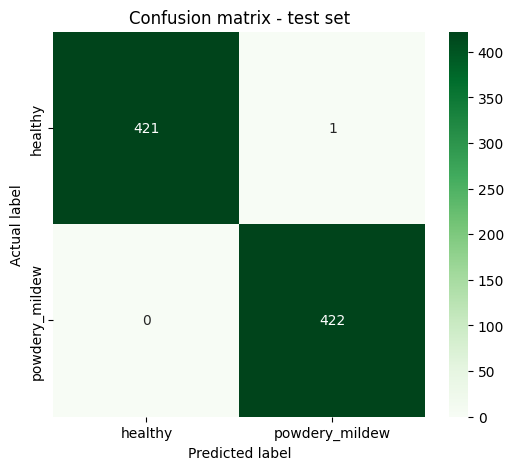

In [12]:
# Confusion matrix and classification report on the test set
y_true = np.concatenate([labels for _, labels in test_set]).astype(int).ravel()
y_prob = model.predict(test_set, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

report = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
pd.DataFrame(report).T.round(3).to_csv(os.path.join(file_path, 'classification_report.csv'))
print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted label')
plt.ylabel('Actual label')
plt.title('Confusion matrix - test set')
plt.savefig(os.path.join(file_path, 'confusion_matrix.png'), bbox_inches='tight', dpi=150)
plt.show()

---

# Does the model meet the business requirement?

In [13]:
if test_accuracy >= TARGET_ACCURACY:
    print(f'SUCCESS: test accuracy {test_accuracy:.2%} meets the '
          f'{TARGET_ACCURACY:.0%} target agreed with the client.')
else:
    print(f'NOT MET: test accuracy {test_accuracy:.2%} is below the '
          f'{TARGET_ACCURACY:.0%} target. Try more epochs or another model version.')

SUCCESS: test accuracy 99.88% meets the 97% target agreed with the client.


---

# Conclusions

* The chosen model (version A) reached **99.88% accuracy** (loss 0.0117) on 844 unseen test images, which **meets the 97% target** in the ML business case. Hypothesis 3 is confirmed.
* **Learning curves:** validation loss was lowest after the first epoch and then rose (to 0.12 by epoch 4) while training loss kept falling, an early sign of overfitting. Early stopping halted training after 4 epochs and restored the weights from the best epoch, so the saved model is the one that generalised best.
* **Confusion matrix:** 843 of 844 test leaves were classified correctly. All 422 infected leaves were detected (recall 1.00), and one healthy leaf was wrongly flagged as powdery mildew. For the business this is the safer error: no infected tree is missed, and the worst case is one unnecessary 1-minute treatment.
* The model and all evaluation files are saved in `outputs/v1/` for the dashboard.